# PathSnap: exploratory data analysis

**Team notebook for report section 2.2 (dataset understanding and EDA).** Everything below is computed from the raw files in this
repo when the notebook runs. No number is typed in by hand.

**Partitions used.** Each section says which one it analyses:

| Partition | Trips | Used for |
|---|---|---|
| `train` | 80 | EDA, model training, cross-validation, decoder tuning |
| `student_test` | 10 | EDA and development comparison only (never trained on) |
| evaluator test | 10 | **Not available to us and never used** |

**To run it:** `data/raw/` must hold the trip folders, and `data/processed/` must exist (`python -m src.features.build_table`); the models are in `models/`. Run from anywhere inside the repo.

**Contents:** 1 Inventory and missing-value analysis · 2 Geography · 3 Sampling, gaps and speed · 4 GPS trajectories and road networks ·
5 Network structure · 6 Reference routes · 7 Labelling and candidate generation · 8 Features · 9 Folium maps · 10 Findings and decisions

In [1]:
import os, sys, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

from src.data.loader import list_trips, load_trip
from src.features.candidates import FEATURES, CAND_RADIUS_M, MAX_CANDS, LABEL_MAX_DIST_M

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
BLUE, ORANGE, GREEN, PURPLE, GREY, RED = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#9a9a9a", "#e0302c"
PCOL = {"train": BLUE, "student_test": ORANGE}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})
print("repo root:", ROOT)

repo root: /home/claude/ml_hackathon


## 1. Inventory and missing-value analysis (`train` and `student_test`)

Each trip is a folder with four whitespace-separated files without headers: `.track` (lon, lat, timestamp), `.nodes` (lon, lat),
`.arcs` (from_node, to_node) and `.route` (reference arc sequence). Node and arc ids are **local to each trip**.
The cell below reads every trip and builds the data-quality log, saved to `results/tables/data_quality.csv`.

In [2]:
def trip_stats(part, tid):
    tr = load_trip(part, tid)                       # EDA only: the reference route is read here, not by the inference path
    t, x, y = tr.track.t.to_numpy(float), tr.track.x.to_numpy(), tr.track.y.to_numpy()
    lon, lat = tr.track.lon.to_numpy(), tr.track.lat.to_numpy()
    dt = np.diff(t); step = np.hypot(np.diff(x), np.diff(y))
    ok = dt > 0
    speed = np.where(ok, step / np.where(ok, dt, 1), np.nan)
    arcs = tr.arcs.to_numpy().astype(int); n_nodes = len(tr.nodes)
    # connected components among nodes that have at least one arc (undirected)
    used = np.zeros(n_nodes, bool); used[arcs.ravel()] = True
    g = coo_matrix((np.ones(len(arcs)), (arcs[:, 0], arcs[:, 1])), shape=(n_nodes, n_nodes))
    ncomp, lab = connected_components(g, directed=False)
    comp_used = len(np.unique(lab[used]))
    dup_directed = int(pd.DataFrame(arcs).duplicated().sum())
    key = arcs[:, 0].astype(np.int64) * n_nodes + arcs[:, 1]; rkey = arcs[:, 1].astype(np.int64) * n_nodes + arcs[:, 0]
    pct_two_way = 100 * float(np.isin(rkey, key).mean())
    route = tr.route.astype(int)
    broken = int((arcs[route[1:], 0] != arcs[route[:-1], 1]).sum()) if len(route) > 1 else 0
    nodes = tr.nodes
    seg = np.hypot(nodes.x.to_numpy()[arcs[:, 1]] - nodes.x.to_numpy()[arcs[:, 0]], nodes.y.to_numpy()[arcs[:, 1]] - nodes.y.to_numpy()[arcs[:, 0]])
    return dict(
        partition=part, trip_id=tid, n_points=len(t), duration_h=(t[-1] - t[0]) / 3600,
        n_nan=int(tr.track[["lon", "lat", "t"]].isna().sum().sum()),
        n_out_of_range=int(((np.abs(lon) > 180) | (np.abs(lat) > 90)).sum()),
        n_dup_timestamps=int((dt == 0).sum()), n_time_reversals=int((dt < 0).sum()),
        pct_dt_eq_1s=100 * float((dt == 1).mean()), max_dt_s=float(dt.max()),
        n_gaps_gt_10s=int((dt > 10).sum()), n_gaps_gt_60s=int((dt > 60).sum()),
        track_km=float(step.sum() / 1000), extent_km=float(np.hypot(np.ptp(x), np.ptp(y)) / 1000),
        median_speed_ms=float(np.nanmedian(speed)), p99_speed_ms=float(np.nanpercentile(speed, 99)), max_speed_ms=float(np.nanmax(speed)),
        n_speed_gt_70ms=int((speed > 70).sum()),
        lon_mean=float(lon.mean()), lat_mean=float(lat.mean()),
        n_nodes=n_nodes, n_arcs=len(arcs), n_self_loops=int((arcs[:, 0] == arcs[:, 1]).sum()), n_duplicate_arcs=dup_directed, pct_arcs_with_reverse=pct_two_way,
        n_components=comp_used, n_isolated_nodes=int((~used).sum()), mean_arc_len_m=float(seg.mean()),
        n_route_arcs=len(route), route_km=float(seg[route].sum() / 1000) if len(route) else np.nan,
        route_breaks=broken, route_arc_out_of_range=int(((route < 0) | (route >= len(arcs))).sum()),
    )

rows = [trip_stats(p, t) for p in ["train", "student_test"] for t in list_trips(p)]
dq = pd.DataFrame(rows)
dq["route_over_track"] = dq.route_km / dq.track_km
(Path("results/tables")).mkdir(parents=True, exist_ok=True); dq.to_csv("results/tables/data_quality.csv", index=False)
print(f"{len(dq)} trips read; log saved to results/tables/data_quality.csv")
dq.groupby("partition").agg(trips=("trip_id", "count"), points_total=("n_points", "sum"), points_min=("n_points", "min"),
                            points_median=("n_points", "median"), points_max=("n_points", "max"),
                            nodes_median=("n_nodes", "median"), arcs_median=("n_arcs", "median")).T

90 trips read; log saved to results/tables/data_quality.csv


partition,student_test,train
trips,10.000,80.000
points_total,"19,160.000","208,417.000"
points_min,262.000,361.000
points_median,"1,420.000","1,529.000"
points_max,"3,958.000","19,313.000"
nodes_median,"6,596.500","9,608.000"
arcs_median,"13,145.000","19,526.500"


In [3]:
miss_cols = ["n_nan", "n_out_of_range", "n_dup_timestamps", "n_time_reversals", "self_loop_arcs", "duplicate_arcs_same_direction", "route_arc_out_of_range"]
dq_view = dq.rename(columns={"n_self_loops": "self_loop_arcs", "n_duplicate_arcs": "duplicate_arcs_same_direction"})
print("Missing / invalid values, summed over all trips of each partition:")
display(dq_view.groupby("partition")[miss_cols].sum().T)
print("Files present per trip:")
files = {p: pd.Series({ext: sum((Path("data/raw") / p / t / f"{t}.{ext}").exists() for t in list_trips(p)) for ext in ["track", "nodes", "arcs", "route"]}) for p in ["train", "student_test"]}
display(pd.DataFrame(files))

Missing / invalid values, summed over all trips of each partition:


partition,student_test,train
n_nan,0,0
n_out_of_range,0,0
n_dup_timestamps,0,0
n_time_reversals,0,0
self_loop_arcs,2,22
duplicate_arcs_same_direction,128,1775
route_arc_out_of_range,0,0


Files present per trip:


,train,student_test
track,80,10
nodes,80,10
arcs,80,10
route,80,10


**Reading this.** There are no missing values, no out-of-range coordinates, no duplicate or reversed timestamps and no route arc ids outside the
arc table, and every trip has all four files. The real data problems are elsewhere: irregular sampling (section 3), disconnected networks
(section 5) and routes that do not match the track (section 6). Section 5 also counts self-loop and duplicated arcs.

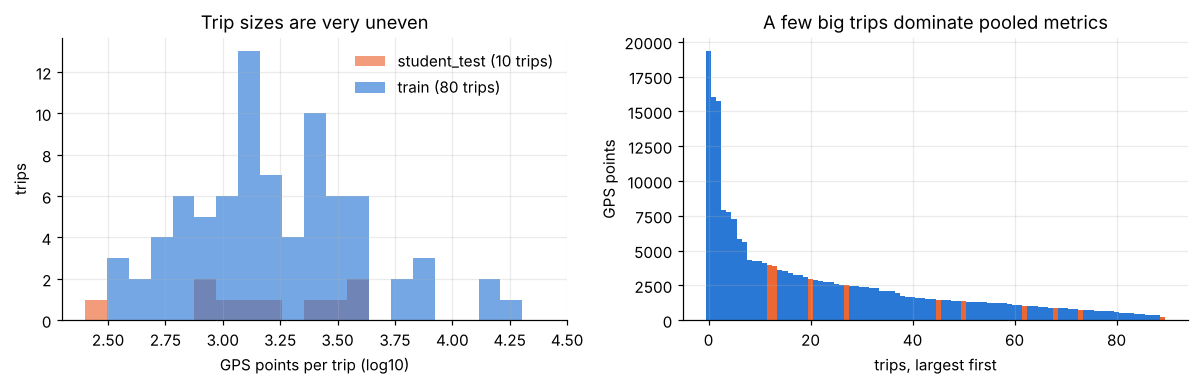

The largest trip has 19313 points and the smallest 262 (74x). Top 10 trips hold 41% of all points.
-> report per-trip metrics as well as pooled ones; group cross-validation by trip.


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for p, g in dq.groupby("partition"):
    ax[0].hist(np.log10(g.n_points), bins=np.linspace(2.4, 4.4, 22), alpha=0.65, color=PCOL[p], label=f"{p} ({len(g)} trips)")
ax[0].set(xlabel="GPS points per trip (log10)", ylabel="trips", title="Trip sizes are very uneven"); ax[0].legend(frameon=False)
big = dq.sort_values("n_points", ascending=False)
ax[1].bar(range(len(big)), big.n_points, color=[PCOL[p] for p in big.partition], width=1.0)
ax[1].set(xlabel="trips, largest first", ylabel="GPS points", title="A few big trips dominate pooled metrics")
plt.tight_layout(); plt.show()
print("The largest trip has", int(dq.n_points.max()), "points and the smallest", int(dq.n_points.min()),
      f"({dq.n_points.max()/dq.n_points.min():.0f}x). Top 10 trips hold {100*big.n_points.head(10).sum()/dq.n_points.sum():.0f}% of all points.")
print("-> report per-trip metrics as well as pooled ones; group cross-validation by trip.")

## 2. Geography (`train` and `student_test`)

Trips come from all over the world. A single map projection cannot serve them all, and a model must not be able to learn "which city".

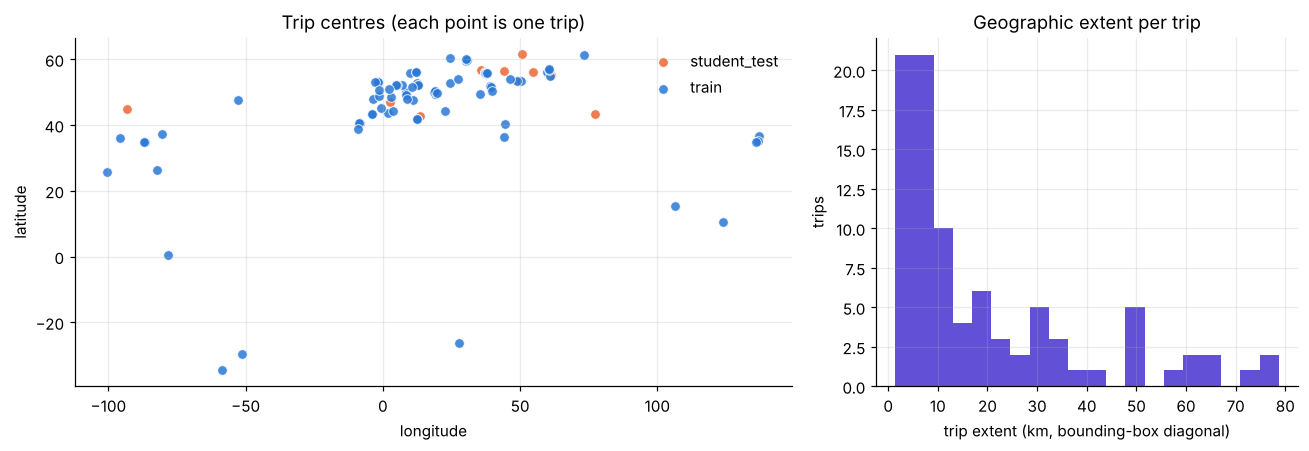

longitude -100 to 137, latitude -35 to 62; extent median 9.5 km, max 78.7 km
-> every trip is projected to metres with its own local azimuthal-equidistant projection (src/data/loader.py).
-> absolute location is never a model feature: train and test trips are in different places.


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.7, 1]})
for p, g in dq.groupby("partition"):
    ax[0].scatter(g.lon_mean, g.lat_mean, s=40, color=PCOL[p], label=p, alpha=0.85, edgecolor="white", linewidth=0.6)
ax[0].set(xlabel="longitude", ylabel="latitude", title="Trip centres (each point is one trip)"); ax[0].legend(frameon=False)
ax[1].hist(dq.extent_km, bins=20, color=PURPLE)
ax[1].set(xlabel="trip extent (km, bounding-box diagonal)", ylabel="trips", title="Geographic extent per trip")
plt.tight_layout(); plt.show()
print(f"longitude {dq.lon_mean.min():.0f} to {dq.lon_mean.max():.0f}, latitude {dq.lat_mean.min():.0f} to {dq.lat_mean.max():.0f}; "
      f"extent median {dq.extent_km.median():.1f} km, max {dq.extent_km.max():.1f} km")
print("-> every trip is projected to metres with its own local azimuthal-equidistant projection (src/data/loader.py).")
print("-> absolute location is never a model feature: train and test trips are in different places.")

## 3. Sampling, time gaps and speed (`train` and `student_test`)

The data is described as 1 Hz. We check how true that is, because gaps and jumps break any assumption that "the next point is one second
and a few metres away".

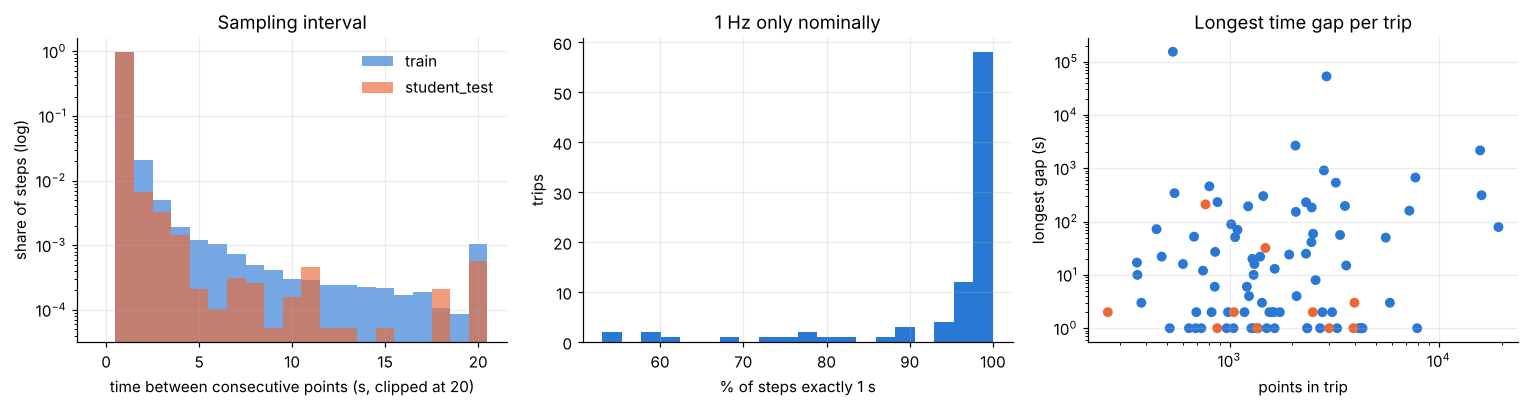

exactly 1 s: 96.7% of all steps | >10 s: 0.27% | >60 s: 0.031%
per-trip share of 1 s steps ranges from 53% to 100%


,partition,trip_id,n_points,max_dt_s,n_gaps_gt_60s
0,train,00000090,536,"153,064.000",1
1,train,00000078,2909,"52,810.000",1
2,train,00000069,2067,"2,658.000",2
3,train,00000021,15783,"2,161.000",2
4,train,00000011,2828,909.000,1
5,train,00000042,7739,670.000,17
6,train,00000081,3224,536.000,15
7,train,00000024,801,458.000,2
8,train,00000044,546,341.000,1
9,train,00000084,16031,312.000,2


In [6]:
dts = {p: np.concatenate([np.diff(load_trip(p, t).track.t.to_numpy(float)) for t in list_trips(p)]) for p in ["train", "student_test"]}
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for p, d in dts.items():
    ax[0].hist(np.clip(d, 0, 20), bins=np.arange(-0.5, 21.5, 1), alpha=0.65, color=PCOL[p], label=p, density=True)
ax[0].set(yscale="log", xlabel="time between consecutive points (s, clipped at 20)", ylabel="share of steps (log)", title="Sampling interval"); ax[0].legend(frameon=False)
ax[1].hist(dq.pct_dt_eq_1s, bins=20, color=BLUE); ax[1].set(xlabel="% of steps exactly 1 s", ylabel="trips", title="1 Hz only nominally")
ax[2].scatter(dq.n_points, dq.max_dt_s, c=[PCOL[p] for p in dq.partition], s=30); ax[2].set(xscale="log", yscale="log", xlabel="points in trip", ylabel="longest gap (s)", title="Longest time gap per trip")
plt.tight_layout(); plt.show()
allv = np.concatenate(list(dts.values()))
print(f"exactly 1 s: {100*(allv==1).mean():.1f}% of all steps | >10 s: {100*(allv>10).mean():.2f}% | >60 s: {100*(allv>60).mean():.3f}%")
print("per-trip share of 1 s steps ranges from", f"{dq.pct_dt_eq_1s.min():.0f}% to {dq.pct_dt_eq_1s.max():.0f}%")
display(dq[dq.max_dt_s > 60][["partition", "trip_id", "n_points", "max_dt_s", "n_gaps_gt_60s"]].sort_values("max_dt_s", ascending=False).reset_index(drop=True))

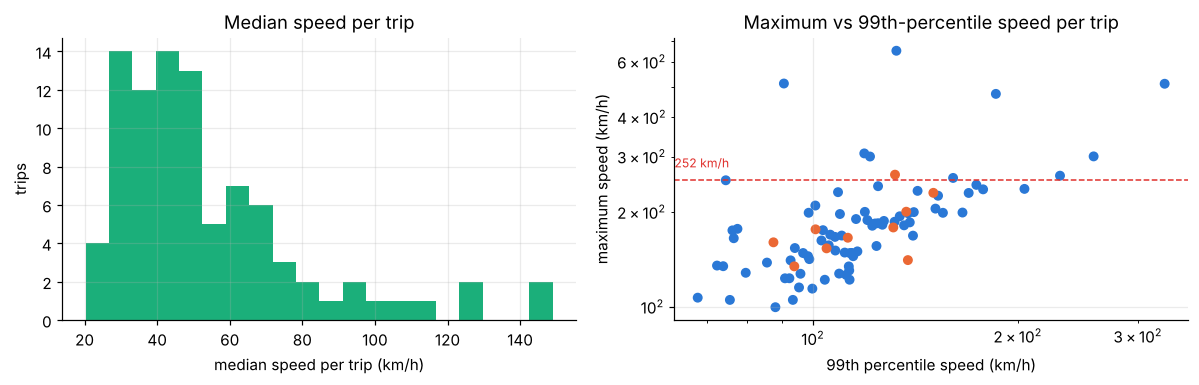

,partition,trip_id,n_points,n_speed_gt_70ms,max_speed_ms,max_dt_s
0,train,00000013,2580,96,141.876,8.000
1,train,00000032,2464,43,83.427,41.000
2,train,00000092,7892,3,85.266,1.000
3,train,00000079,689,2,180.594,1.000
4,train,00000043,2322,2,131.754,230.000
5,train,00000008,3093,1,70.058,2.000
6,train,00000001,1315,1,72.445,16.000
7,train,00000053,1304,1,71.268,10.000
8,train,00000033,5844,1,142.125,3.000
9,train,00000057,1645,1,83.342,13.000


-> steps above 70 m/s (252 km/h) are GPS jumps ('teleports'), not driving. The HMM treats big jumps and big gaps with a reset/widening rule.


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(dq.median_speed_ms * 3.6, bins=20, color=GREEN); ax[0].set(xlabel="median speed per trip (km/h)", ylabel="trips", title="Median speed per trip")
ax[1].scatter(dq.p99_speed_ms * 3.6, dq.max_speed_ms * 3.6, c=[PCOL[p] for p in dq.partition], s=30)
ax[1].set(xscale="log", yscale="log", xlabel="99th percentile speed (km/h)", ylabel="maximum speed (km/h)", title="Maximum vs 99th-percentile speed per trip")
ax[1].axhline(70 * 3.6, color=RED, ls="--", lw=1); ax[1].text(ax[1].get_xlim()[0], 70 * 3.6 * 1.1, "252 km/h", color=RED, fontsize=8)
plt.tight_layout(); plt.show()
display(dq[dq.n_speed_gt_70ms > 0][["partition", "trip_id", "n_points", "n_speed_gt_70ms", "max_speed_ms", "max_dt_s"]].sort_values("n_speed_gt_70ms", ascending=False).reset_index(drop=True))
print("-> steps above 70 m/s (252 km/h) are GPS jumps ('teleports'), not driving. The HMM treats big jumps and big gaps with a reset/widening rule.")

## 4. GPS trajectories and road networks (`train` and `student_test`)

Blue dots are the noisy GPS points, grey is the road network, green is the reference route. All in per-trip local metres.
The trips shown: the smallest student trip, a trip with a time gap, a big student trip, and four training trips chosen for what they show.

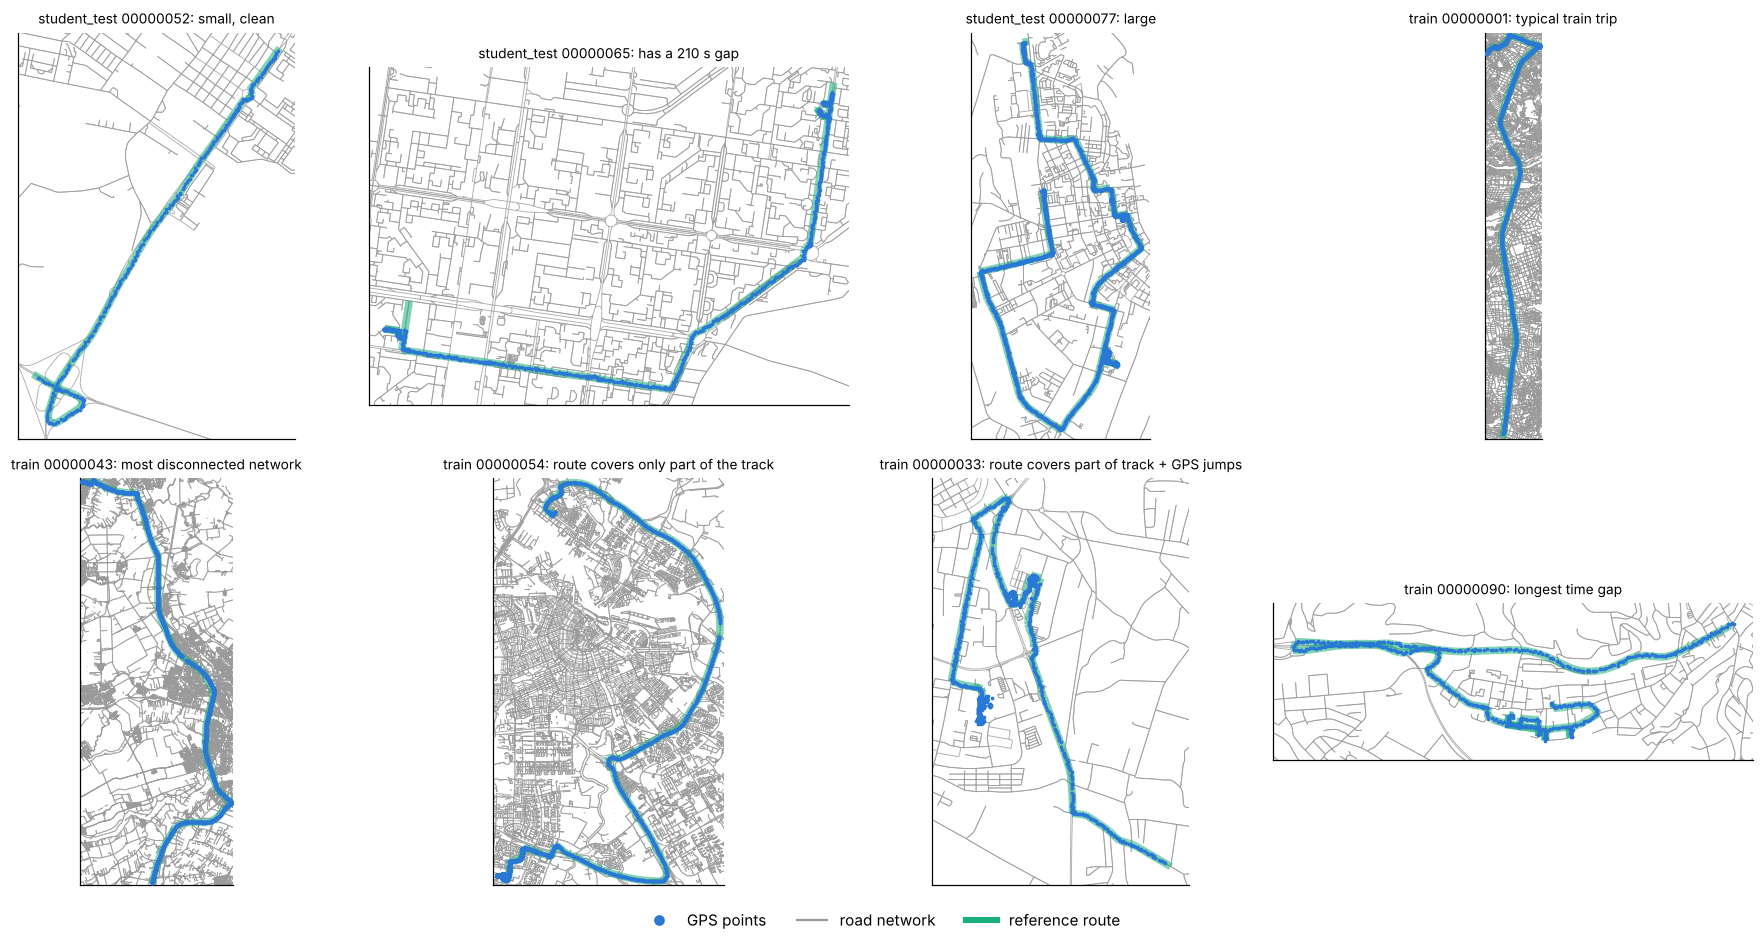

In [8]:
def plot_trip(ax, part, tid, pad=150, title=None):
    tr = load_trip(part, tid)
    n = tr.nodes; a = tr.arcs.to_numpy().astype(int)
    nx, ny = n.x.to_numpy(), n.y.to_numpy()
    xs, ys = [tr.track.x.to_numpy()], [tr.track.y.to_numpy()]
    if len(tr.route):                                  # frame the route too, so a route that is far from the track is visible
        rr = a[tr.route.astype(int)].ravel(); xs.append(nx[rr]); ys.append(ny[rr])
    xs, ys = np.concatenate(xs), np.concatenate(ys)
    x0, x1, y0, y1 = xs.min() - pad, xs.max() + pad, ys.min() - pad, ys.max() + pad
    keep = ((nx[a[:, 0]] > x0) & (nx[a[:, 0]] < x1) & (ny[a[:, 0]] > y0) & (ny[a[:, 0]] < y1)) | ((nx[a[:, 1]] > x0) & (nx[a[:, 1]] < x1) & (ny[a[:, 1]] > y0) & (ny[a[:, 1]] < y1))
    segs = np.stack([np.c_[nx[a[keep, 0]], ny[a[keep, 0]]], np.c_[nx[a[keep, 1]], ny[a[keep, 1]]]], axis=1)
    from matplotlib.collections import LineCollection
    ax.add_collection(LineCollection(segs, colors=GREY, linewidths=0.6, alpha=0.8))
    if len(tr.route):
        r = a[tr.route.astype(int)]
        ax.add_collection(LineCollection(np.stack([np.c_[nx[r[:, 0]], ny[r[:, 0]]], np.c_[nx[r[:, 1]], ny[r[:, 1]]]], axis=1), colors=GREEN, linewidths=5, alpha=0.55))
    ax.scatter(tr.track.x, tr.track.y, s=2, color=BLUE, zorder=3)
    ax.set(xlim=(x0, x1), ylim=(y0, y1), aspect="equal", xticks=[], yticks=[]); ax.grid(False)
    ax.set_title(title or f"{part} {tid}  ({len(tr.track):,} pts)", fontsize=9)

picks = [("student_test", "00000052", "small, clean"), ("student_test", "00000065", "has a 210 s gap"), ("student_test", "00000077", "large"),
         ("train", "00000001", "typical train trip")]
q = dq[dq.partition == "train"]
picks += [("train", q.sort_values("n_components").trip_id.iloc[-1], "most disconnected network"),
          ("train", "00000054", "route covers only part of the track"), ("train", "00000033", "route covers part of track + GPS jumps"),
          ("train", q.sort_values("max_dt_s").trip_id.iloc[-1], "longest time gap")]
fig, axs = plt.subplots(2, 4, figsize=(17, 8.6))
for ax, (p, t, why) in zip(axs.ravel(), picks):
    plot_trip(ax, p, t, title=f"{p} {t}: {why}")
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", color=BLUE, label="GPS points"), plt.Line2D([], [], color=GREY, label="road network"),
                    plt.Line2D([], [], color=GREEN, lw=4, label="reference route")], loc="lower center", ncol=3, frameon=False)
plt.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

## 5. Road-network structure (`train` and `student_test`)

Connected components are computed on the undirected graph of nodes that have at least one arc.

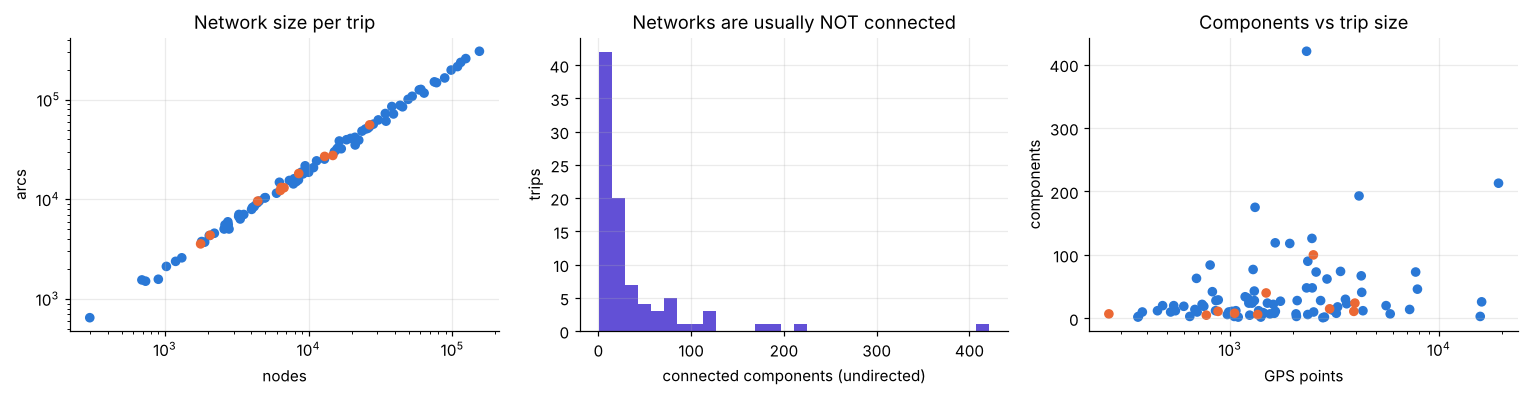

partition                     student_test       train
n_nodes               min        1,770.000     299.000
                      median     6,596.500   9,608.000
                      max       26,635.000 155,003.000
n_arcs                min        3,577.000     649.000
                      median    13,145.000  19,526.500
                      max       56,027.000 307,392.000
n_components          min            5.000       1.000
                      median        11.000      20.000
                      max          100.000     421.000
n_isolated_nodes      min            0.000       0.000
                      median         0.000       0.000
                      max            0.000       0.000
n_self_loops          min            0.000       0.000
                      median         0.000       0.000
                      max            2.000       8.000
n_duplicate_arcs      min            0.000       0.000
                      median         3.500       2.000
                      max           62.000     322.000
pct_arcs_with_reverse min           85.547      35.133
                      median        93.261      95.112
                      max           99.565     100.000
mean_arc_len_m        min           26.875      15.052
                      median        48.967      40.138
                      max           96.918     169.119

trips with more than 1 component: 89 of 90; most components in one trip: 421
trips with self-loop arcs: 9; trips with duplicated directed arcs (same from and to): 60
share of arcs that have a reverse twin (two-way road): median 95% per trip
-> two directions of one road are separate arcs, so the heading features and has_reverse matter: the same road can be the right or the wrong way.
-> a vehicle can only follow connected arcs, but the network has many pieces, so the HMM transition model needs a
   'disconnected' fallback and a reset rule; hop distance is computed on the arc graph, not the straight-line distance.


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.7))
ax[0].scatter(dq.n_nodes, dq.n_arcs, c=[PCOL[p] for p in dq.partition], s=28); ax[0].set(xscale="log", yscale="log", xlabel="nodes", ylabel="arcs", title="Network size per trip")
ax[1].hist(dq.n_components, bins=30, color=PURPLE); ax[1].set(xlabel="connected components (undirected)", ylabel="trips", title="Networks are usually NOT connected")
ax[2].scatter(dq.n_points, dq.n_components, c=[PCOL[p] for p in dq.partition], s=28); ax[2].set(xscale="log", xlabel="GPS points", ylabel="components", title="Components vs trip size")
plt.tight_layout(); plt.show()
cols = ["n_nodes", "n_arcs", "n_components", "n_isolated_nodes", "n_self_loops", "n_duplicate_arcs", "pct_arcs_with_reverse", "mean_arc_len_m"]
display(dq.groupby("partition")[cols].agg(["min", "median", "max"]).T)
print(f"trips with more than 1 component: {(dq.n_components > 1).sum()} of {len(dq)}; most components in one trip: {dq.n_components.max()}")
print(f"trips with self-loop arcs: {(dq.n_self_loops > 0).sum()}; trips with duplicated directed arcs (same from and to): {(dq.n_duplicate_arcs > 0).sum()}")
print(f"share of arcs that have a reverse twin (two-way road): median {dq.pct_arcs_with_reverse.median():.0f}% per trip")
print("-> two directions of one road are separate arcs, so the heading features and has_reverse matter: the same road can be the right or the wrong way.")
print("-> a vehicle can only follow connected arcs, but the network has many pieces, so the HMM transition model needs a")
print("   'disconnected' fallback and a reset rule; hop distance is computed on the arc graph, not the straight-line distance.")

## 6. Reference routes (`train` and `student_test`)

`.route` is the only ground truth. It is a sequence of arc ids, **not** per-point labels. We check how well it agrees with the GPS track.

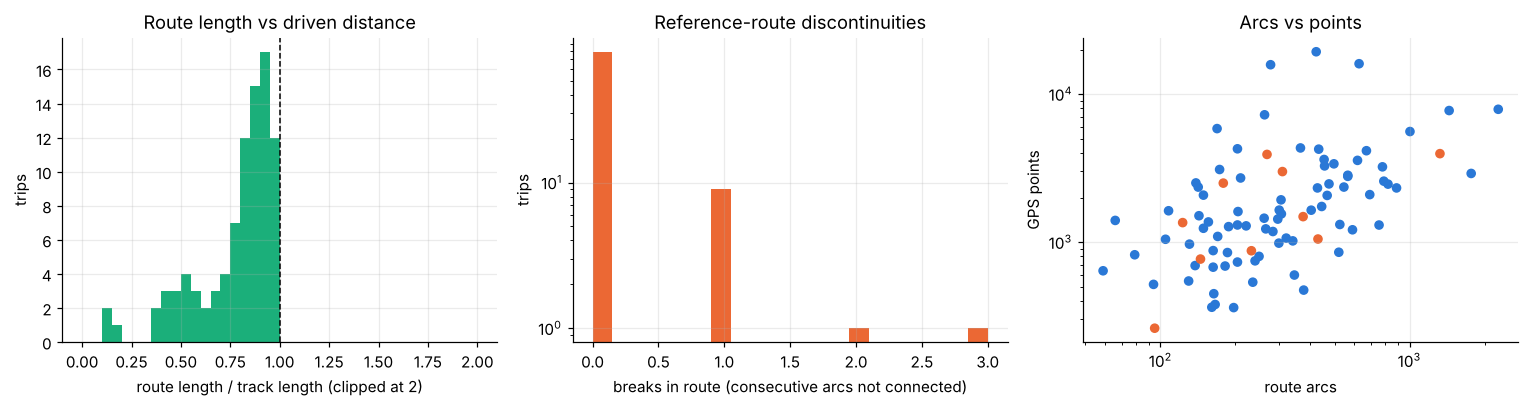

route/track length ratio: median 0.85 | 5th-95th percentile 0.40-0.97


,partition,trip_id,n_route_arcs,route_breaks
0,train,00000019,545,3
1,train,00000075,108,2
2,train,00000002,262,1
3,train,00000033,169,1
4,train,00000041,340,1
5,train,00000042,1440,1
6,train,00000069,467,1
7,train,00000080,139,1
8,train,00000086,671,1
9,train,00000089,265,1


11 trips have at least one break in the reference route itself.
-> the reference route is not perfectly connected, so 'route continuity' of a prediction must be read against the reference's own continuity.


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(dq.route_over_track.clip(0, 2), bins=np.linspace(0, 2, 41), color=GREEN); ax[0].axvline(1, color="k", lw=1, ls="--")
ax[0].set(xlabel="route length / track length (clipped at 2)", ylabel="trips", title="Route length vs driven distance")
ax[1].hist(dq.route_breaks, bins=20, color=ORANGE); ax[1].set(yscale="log", xlabel="breaks in route (consecutive arcs not connected)", ylabel="trips", title="Reference-route discontinuities")
ax[2].scatter(dq.n_route_arcs, dq.n_points, c=[PCOL[p] for p in dq.partition], s=28); ax[2].set(xscale="log", yscale="log", xlabel="route arcs", ylabel="GPS points", title="Arcs vs points")
plt.tight_layout(); plt.show()
print("route/track length ratio: median", f"{dq.route_over_track.median():.2f}", "| 5th-95th percentile", f"{dq.route_over_track.quantile(.05):.2f}-{dq.route_over_track.quantile(.95):.2f}")
display(dq[dq.route_breaks > 0][["partition", "trip_id", "n_route_arcs", "route_breaks"]].sort_values("route_breaks", ascending=False).reset_index(drop=True))
print(f"{(dq.route_breaks > 0).sum()} trips have at least one break in the reference route itself.")
print("-> the reference route is not perfectly connected, so 'route continuity' of a prediction must be read against the reference's own continuity.")

## 7. Labelling and candidate generation (`train` and `student_test`)

**Why candidate scoring.** We cannot classify "which of thousands of arcs" directly, and arc ids mean nothing across trips. So for each GPS point
we take the road arcs within 40 m (at most 12 nearest) as *candidates* and ask a model: is this the arc the vehicle was on? Each (point, candidate)
pair is one row, labelled 1 or 0.

**How labels are made.** There are no per-point labels, so we derive them: each point is matched to the reference route with an order-aware forward
pointer (it can only move forward along the route, with a small allowed step back). A point farther than 30 m from the route gets no label.
Trips where fewer than half of the points get a label cannot be trusted and are excluded from training and evaluation.

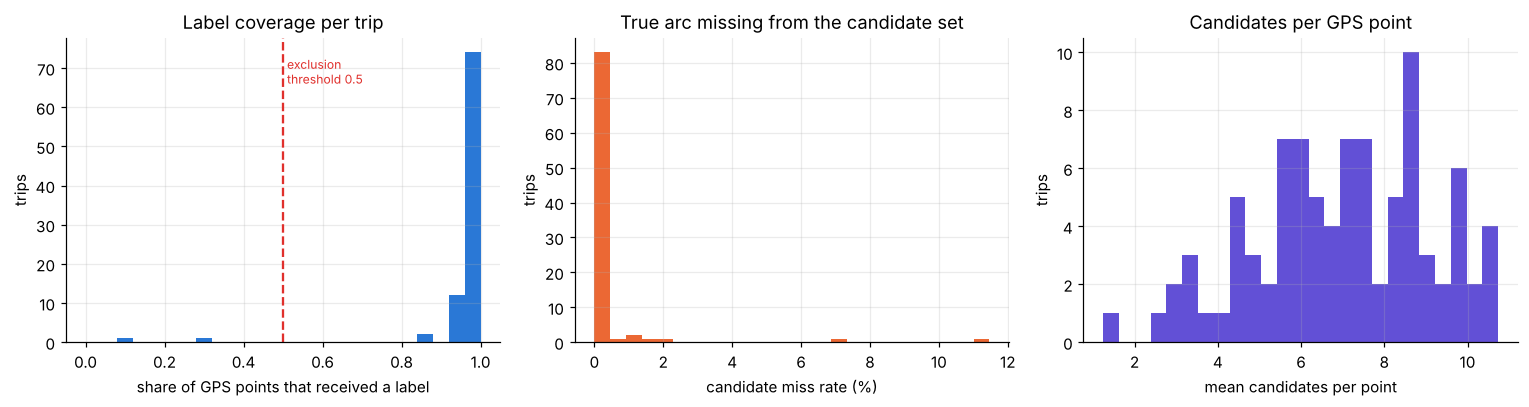

excluded (label_frac < 0.5): train 00000033 (29% labelled), train 00000054 (11% labelled)
all other trips: label coverage 86%-100%, median 100%
pooled candidate miss rate at 40 m: 0.180% | mean candidates per point: 5.8


In [11]:
tq = pd.read_csv("results/tables/trip_quality.csv", dtype={"trip_id": str})
tq["cand_miss_pct"] = 100 * tq.candidate_miss_rate
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(tq.label_frac, bins=np.linspace(0, 1, 26), color=BLUE); ax[0].axvline(0.5, color=RED, ls="--"); ax[0].text(0.51, ax[0].get_ylim()[1] * 0.85, "exclusion\nthreshold 0.5", color=RED, fontsize=8)
ax[0].set(xlabel="share of GPS points that received a label", ylabel="trips", title="Label coverage per trip")
ax[1].hist(tq.cand_miss_pct, bins=25, color=ORANGE); ax[1].set(xlabel="candidate miss rate (%)", ylabel="trips", title="True arc missing from the candidate set")
ax[2].hist(tq.mean_cands, bins=25, color=PURPLE); ax[2].set(xlabel="mean candidates per point", ylabel="trips", title="Candidates per GPS point")
plt.tight_layout(); plt.show()
bad = tq[tq.label_frac < 0.5]
print("excluded (label_frac < 0.5):", ", ".join(f"{r.partition} {r.trip_id} ({100*r.label_frac:.0f}% labelled)" for r in bad.itertuples()))
print(f"all other trips: label coverage {100*tq[tq.label_frac >= 0.5].label_frac.min():.0f}%-{100*tq[tq.label_frac >= 0.5].label_frac.max():.0f}%, "
      f"median {100*tq.label_frac.median():.0f}%")
print(f"pooled candidate miss rate at {CAND_RADIUS_M:.0f} m: {100*np.average(tq.candidate_miss_rate, weights=tq.n_labelled):.3f}% | mean candidates per point: {np.average(tq.mean_cands, weights=tq.n_points):.1f}")

**Choosing the candidate radius.** A small radius gives few candidates but can miss the true arc when GPS noise is large; a big one adds candidates that
only make the model's job harder. The next cell measures both effects from the real training table: the share of labelled points whose true arc lies
within radius *r* (coverage), against the average number of candidates per point (cost).

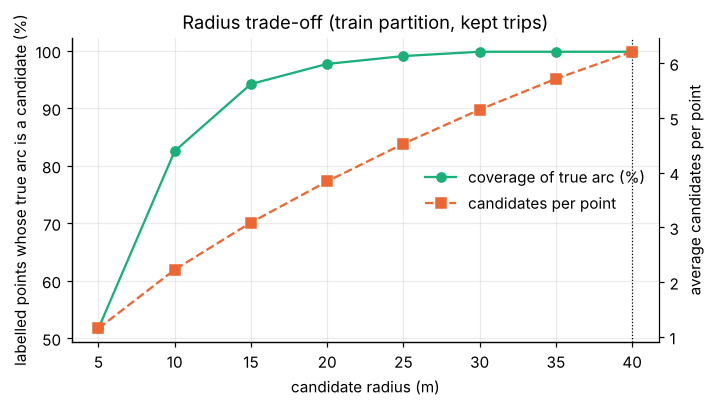

 radius_m  coverage_%  candidates_per_point
        5      51.710                 1.150
       10      82.560                 2.230
       15      94.220                 3.090
       20      97.710                 3.840
       25      99.080                 4.530
       30      99.830                 5.150
       35      99.830                 5.720
       40      99.830                 6.210

Chosen: 40 m radius, at most 12 nearest candidates.
Caveat: labels only exist for points within 30 m of the route, so coverage cannot be measured beyond 30 m and the curve is flat there by construction.
The 30-40 m band is a safety margin for noisy points; it costs about one extra candidate per point.


In [12]:
cand = pd.read_parquet("data/processed/candidates_train.parquet", columns=["trip_id", "pt", "dist", "label", "pt_has_label"])
cand = cand[~cand.trip_id.isin(bad.trip_id)]
true_d = cand[(cand.label == 1)].groupby(["trip_id", "pt"]).dist.min()
n_lab_pts = cand[cand.pt_has_label].groupby(["trip_id", "pt"]).ngroups
radii = np.array([5, 10, 15, 20, 25, 30, 35, 40])
cover = [100 * (true_d <= r).sum() / n_lab_pts for r in radii]
n_pts = cand.groupby(["trip_id", "pt"]).ngroups
cost = [(cand.dist <= r).sum() / n_pts for r in radii]
fig, ax = plt.subplots(figsize=(6.6, 3.8)); ax2 = ax.twinx(); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.plot(radii, cover, "-o", color=GREEN, label="coverage of true arc (%)"); ax2.plot(radii, cost, "--s", color=ORANGE, label="candidates per point")
ax.set(xlabel="candidate radius (m)", ylabel="labelled points whose true arc is a candidate (%)", title="Radius trade-off (train partition, kept trips)")
ax2.set_ylabel("average candidates per point"); ax.axvline(CAND_RADIUS_M, color="k", lw=0.8, ls=":")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, frameon=False, loc="center right")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"radius_m": radii, "coverage_%": np.round(cover, 2), "candidates_per_point": np.round(cost, 2)}).to_string(index=False))
print(f"\nChosen: {CAND_RADIUS_M:.0f} m radius, at most {MAX_CANDS} nearest candidates.")
print(f"Caveat: labels only exist for points within {LABEL_MAX_DIST_M:.0f} m of the route, so coverage cannot be measured beyond {LABEL_MAX_DIST_M:.0f} m and the curve is flat there by construction.")
print("The 30-40 m band is a safety margin for noisy points; it costs about one extra candidate per point.")

## 8. Features (`train` partition, kept trips)

27 numeric features per (point, candidate) row, in six groups. **None uses absolute location or arc/node ids.** All distances are in the trip's local metres.

In [13]:
groups = {
 "Distance to the arc":      (["dist", "dist_rank", "dist_minus_min", "n_cands"], "The nearest road is usually the right one; rank and gap to the nearest candidate tell the model how clear-cut that is."),
 "Position on the arc":      (["t_frac", "along_m", "arc_len"], "Where the point projects along the arc (start, middle, end) and how long the arc is. Helps at junctions and short arcs."),
 "Direction":                (["cos_h1", "cos_h3"], "Cosine of the angle between the travel heading (1 and 3 steps ahead) and the arc direction. Separates opposite directions of the same road."),
 "Motion":                   (["speed", "log_dt_prev", "log_dt_next"], "Speed and time gaps to neighbours: stationary or sparse points are less reliable."),
 "Topology (arc graph)":     (["has_reverse", "conn_prev", "rev_prev", "conn_next", "rev_next", "deg_from", "deg_to"], "Is this arc connected to the best arc of the previous/next point? Does it have a reverse twin? How many roads meet at its ends?"),
 "Neighbour context":        (["d_m5", "d_m3", "d_m1", "d_p1", "d_p3", "d_p5", "d_ctx_mean", "d_ctx_max"], "Distance of the same arc to the points 1, 3, 5 steps before and after: a true arc stays close along the trip; a crossing road does not."),
}
assert sorted(sum((g[0] for g in groups.values()), [])) == sorted(FEATURES), "feature table out of sync with FEATURES"
display(pd.DataFrame([{"group": k, "n": len(v[0]), "features": ", ".join(v[0]), "why": v[1]} for k, v in groups.items()]).style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}))
print(len(FEATURES), "features in total")

,group,n,features,why
0,Distance to the arc,4,"dist, dist_rank, dist_minus_min, n_cands",The nearest road is usually the right one; rank and gap to the nearest candidate tell the model how clear-cut that is.
1,Position on the arc,3,"t_frac, along_m, arc_len","Where the point projects along the arc (start, middle, end) and how long the arc is. Helps at junctions and short arcs."
2,Direction,2,"cos_h1, cos_h3",Cosine of the angle between the travel heading (1 and 3 steps ahead) and the arc direction. Separates opposite directions of the same road.
3,Motion,3,"speed, log_dt_prev, log_dt_next",Speed and time gaps to neighbours: stationary or sparse points are less reliable.
4,Topology (arc graph),7,"has_reverse, conn_prev, rev_prev, conn_next, rev_next, deg_from, deg_to",Is this arc connected to the best arc of the previous/next point? Does it have a reverse twin? How many roads meet at its ends?
5,Neighbour context,8,"d_m5, d_m3, d_m1, d_p1, d_p3, d_p5, d_ctx_mean, d_ctx_max","Distance of the same arc to the points 1, 3, 5 steps before and after: a true arc stays close along the trip; a crossing road does not."


27 features in total


1,110,638 labelled candidate rows from 78 trips and 178,612 GPS points
class balance: 16.1% positive (the true arc), 83.9% negative -> about 1 positive per 6.2 candidates


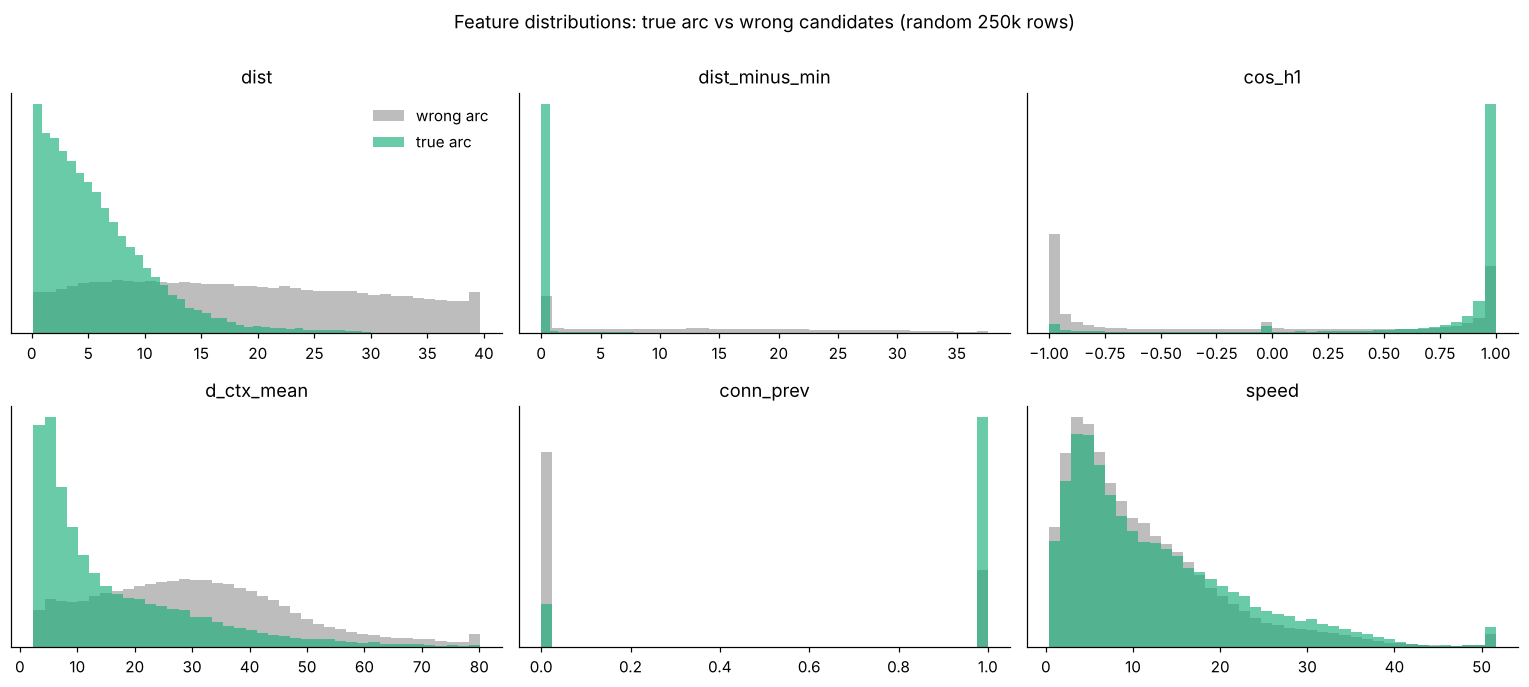

In [14]:
T = pd.read_parquet("data/processed/candidates_train.parquet")
T = T[~T.trip_id.isin(bad.trip_id) & T.pt_has_label]
print(f"{len(T):,} labelled candidate rows from {T.trip_id.nunique()} trips and {T.groupby(['trip_id','pt']).ngroups:,} GPS points")
pos = T.label.mean()
print(f"class balance: {100*pos:.1f}% positive (the true arc), {100*(1-pos):.1f}% negative -> about 1 positive per {1/pos:.1f} candidates")
S = T.sample(250_000, random_state=42)
show = ["dist", "dist_minus_min", "cos_h1", "d_ctx_mean", "conn_prev", "speed"]
fig, axs = plt.subplots(2, 3, figsize=(14, 6.2))
for ax, f in zip(axs.ravel(), show):
    lo, hi = S[f].quantile([0.005, 0.995])
    for lab, c, name in [(0, GREY, "wrong arc"), (1, GREEN, "true arc")]:
        ax.hist(S.loc[S.label == lab, f].clip(lo, hi), bins=40, alpha=0.65, color=c, label=name, density=True)
    ax.set(title=f, yticks=[]); ax.grid(False)
axs[0, 0].legend(frameon=False)
plt.suptitle("Feature distributions: true arc vs wrong candidates (random 250k rows)", y=1.0); plt.tight_layout(); plt.show()

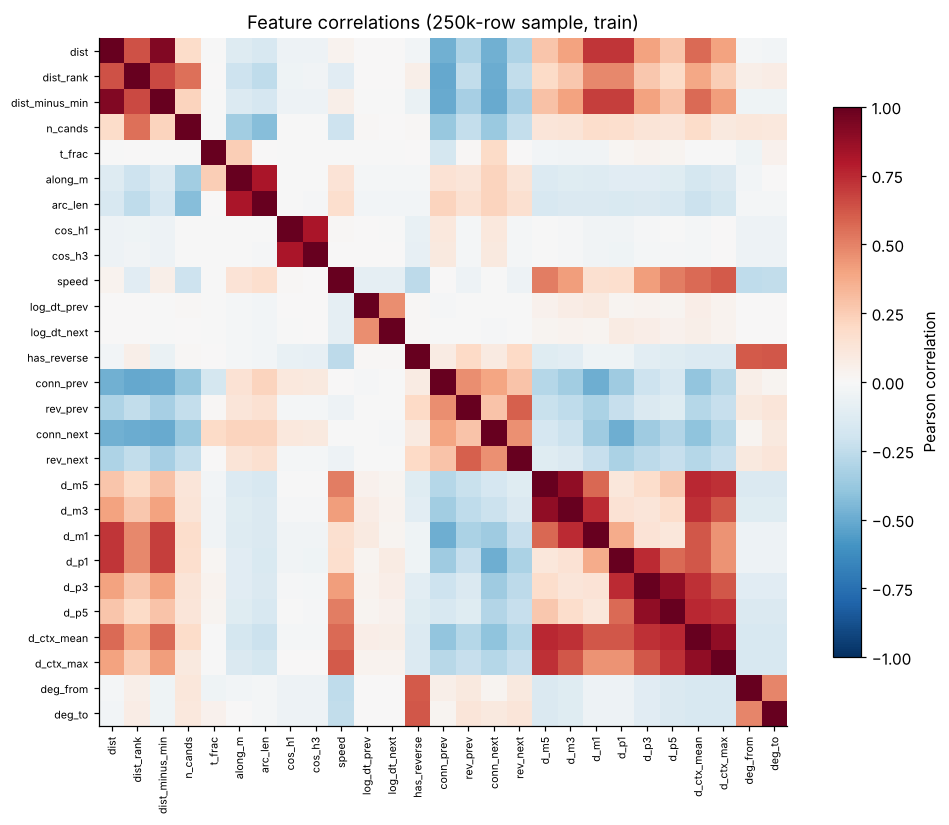

most correlated pairs:
dist        dist_minus_min   0.927
d_m5        d_m3             0.891
d_p3        d_p5             0.890
d_ctx_mean  d_ctx_max        0.886
along_m     arc_len          0.817
cos_h1      cos_h3           0.813
-> correlated features are kept: tree models and the MLP cope with redundancy, and each group answers a different question.


In [15]:
corr = S[FEATURES].corr()
fig, ax = plt.subplots(figsize=(9.5, 7.6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7); ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=7)
plt.colorbar(im, shrink=0.8, label="Pearson correlation"); ax.set_title("Feature correlations (250k-row sample, train)")
plt.tight_layout(); plt.show()
c = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().abs().sort_values(ascending=False)
print("most correlated pairs:"); print(c.head(6).round(3).to_string())
print("-> correlated features are kept: tree models and the MLP cope with redundancy, and each group answers a different question.")

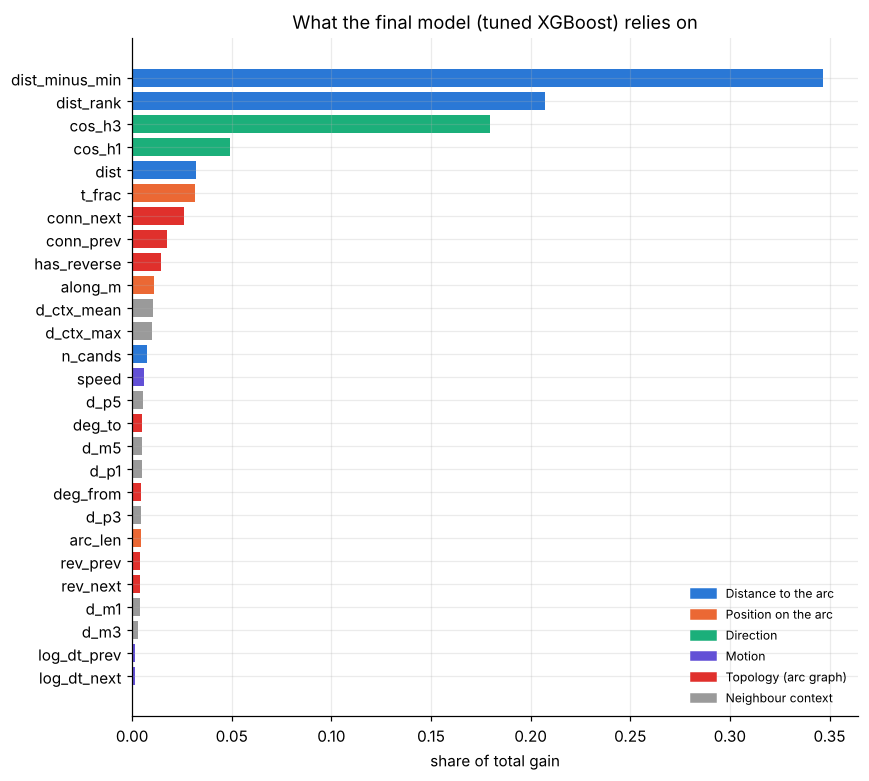

dist_minus_min   0.347
dist_rank        0.207
cos_h3           0.180
cos_h1           0.049
dist             0.032
t_frac           0.032
conn_next        0.026
conn_prev        0.017


In [16]:
import joblib
bundle = joblib.load("models/xgb_tuned.joblib")
gain = pd.Series(bundle["model"].get_booster().get_score(importance_type="gain")); gain.index = [FEATURES[int(i[1:])] if i.startswith("f") and i[1:].isdigit() else i for i in gain.index]
gain = (gain / gain.sum()).sort_values()
gcol = {f: k for k, (fs, _) in groups.items() for f in fs}
palette = dict(zip(groups, [BLUE, ORANGE, GREEN, PURPLE, RED, GREY]))
fig, ax = plt.subplots(figsize=(8, 7.2))
ax.barh(gain.index, gain.values, color=[palette[gcol[f]] for f in gain.index]); ax.set(xlabel="share of total gain", title="What the final model (tuned XGBoost) relies on")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=k) for k, c in palette.items()], frameon=False, loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()
print(gain.sort_values(ascending=False).head(8).round(3).to_string())

**Feature reading.** The final model leans mostly on *relative* distance (how much farther a candidate is than the nearest one, and its rank)
and on heading agreement (`cos_h3`, `cos_h1`). Raw distance alone matters much less than the gap to the nearest candidate.
The topology and neighbour-context features each carry little gain individually.
Caution: gain importance splits credit between correlated features (see the heatmap), so a small gain does not prove a feature is useless; we have not run a
feature-group ablation, so we do not claim one. What the whole-path HMM adds on top is measured separately (classifier-only vs classifier + HMM).

## 9. Folium maps (`student_test` partition)

The maps are produced by `src/visualization/maps.py` from our real pipeline: the red line is the output of the tuned XGBoost classifier plus
HMM/Viterbi decoding, the green line is the reference route, the orange dashed line is the classifier alone, and blue dots are the raw GPS points.
Use the layer control (top right) to switch layers; the purple dots mark the places where the HMM overruled the classifier.
Interactive HTML files are committed in `results/maps/`.

In [17]:
from src.visualization.maps import build_map, save_map
m = build_map("student_test", "00000052")
m

In [18]:
# Two more representative trips are saved as standalone HTML (open them in a browser): one with a long time gap, one of the hardest.
for tid in ["00000065", "00000077"]:
    print(save_map("student_test", tid))

/home/claude/ml_hackathon/results/maps/student_test_00000065_prediction.html


/home/claude/ml_hackathon/results/maps/student_test_00000077_prediction.html


## 10. Findings and the decisions they led to

| # | What the data showed | Evidence (section) | What we did about it |
|---|---|---|---|
| 1 | No missing values or invalid coordinates, but several real defects | 1 | Cleaning is about structure (gaps, jumps, labels), not imputation |
| 2 | Trips span the whole world | 2 | Per-trip local projection; no location features |
| 3 | Sampling is only nominally 1 Hz; some huge gaps and GPS jumps | 3 | Time-gap features; HMM reset/widening for large gaps and jumps |
| 4 | Trip sizes differ by more than 50x | 1 | Group CV by trip; report per-trip as well as pooled metrics |
| 5 | Road networks are fragmented; two-way roads are two arcs; a few self-loops | 5 | Hop distance on the arc graph with a disconnected-pair fallback in the HMM |
| 6 | Reference routes sometimes break or do not match the track | 4, 6 | Order-aware labelling; trips with under 50% labelled points are excluded; continuity read against the reference's own |
| 7 | No per-point labels exist | 7 | Derived labels; candidate scoring with a 40 m radius (about 0.2% of labelled points miss their true arc, about 6 candidates per point) |
| 8 | The nearest road is often but not always the right one | 8 | 27 features: relative distance and heading carry most of the signal; the HMM adds whole-path consistency |